In [1]:
from mpl_toolkits import mplot3d
import numpy as np
import matplotlib.pyplot as plt

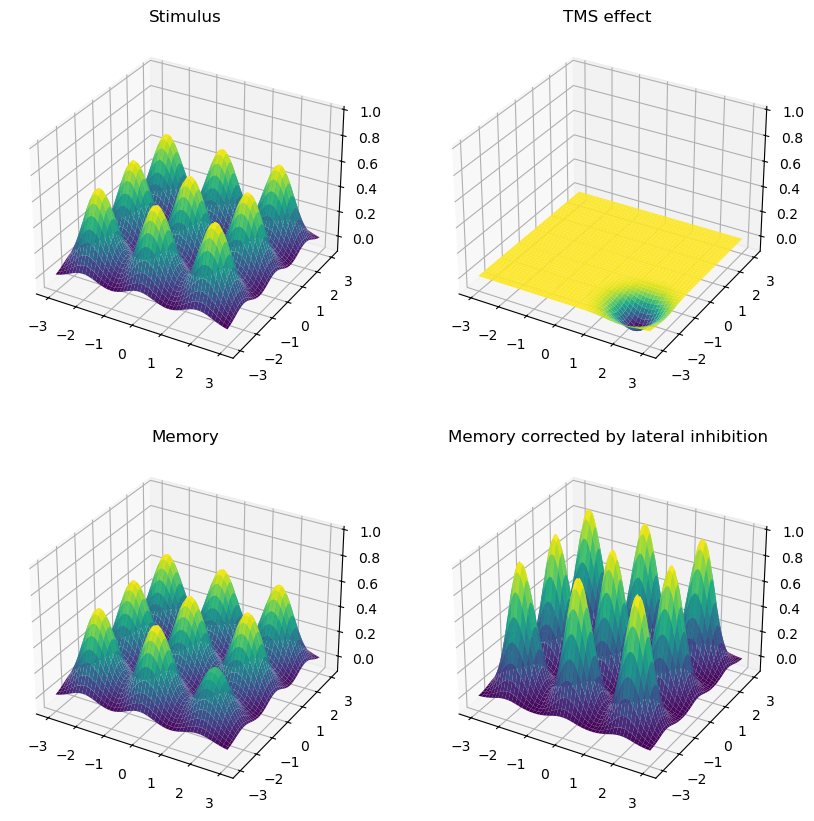

In [24]:
def generate_gaussian(mu_x, mu_y, sigma):
    sigma_x = sigma
    sigma_y = sigma
    # Parameters for the 2D Gaussian
    size = 100  # size of the grid

    # Generate a grid of (x, y) coordinates
    x = np.linspace(-3, 3, size)
    y = np.linspace(-3, 3, size)
    x, y = np.meshgrid(x, y)

    # Compute the 2D Gaussian function
    z = (1/(2 * np.pi * sigma_x * sigma_y)) * np.exp(-((x - mu_x)**2 / (2 * sigma_x**2) + (y - mu_y)**2 / (2 * sigma_y**2)))

    return x, y, z

def generate_negative_gaussian(mu_x, mu_y, sigma):
    sigma_x = sigma
    sigma_y = sigma
    # Parameters for the 2D Gaussian
    size = 100  # size of the grid

    # Generate a grid of (x, y) coordinates
    x = np.linspace(-3, 3, size)
    y = np.linspace(-3, 3, size)
    x, y = np.meshgrid(x, y)

    # Compute the 2D Gaussian function
    z = (1/(2 * np.pi * sigma_x * sigma_y)) * np.exp(-((x - mu_x)**2 / (2 * sigma_x**2) + (y - mu_y)**2 / (2 * sigma_y**2)))
    # scale down z
    z = z * -0.3

    return x, y, z

from itertools import product
# Stimulus
sigma = 0.5
z_stimul = np.zeros((100, 100))
x_vec = [-2, 0, 2]
y_vec = [-2, 0, 2]
for x, y in product(x_vec, y_vec):
    x_stimul, y_stimul, z = generate_gaussian(x, y, sigma)
    z_stimul = np.nansum([z_stimul, z], axis=0)
# mu_x_stimul, mu_y_stimul = 2, -2
# x_stimul, y_stimul, z_stimul = generate_gaussian(mu_x_stimul, mu_y_stimul, sigma)

# TMS effect
mu_x_tms, mu_y_tms = 2, -2
x_tms, y_tms, z_tms = generate_negative_gaussian(mu_x_tms, mu_y_tms, sigma)

# Memory
x_memory, y_memory, z_memory = x_stimul, y_stimul, z_stimul+z_tms

# Memory corrected by lateral inhibition
z_memory_corrected = np.zeros((100, 100))
for x, y in product(x_vec, y_vec):
    x_memory, y_memory, z = generate_gaussian(x, y, 0.4)
    z_memory_corrected = np.nansum([z_memory_corrected, z], axis=0)


# Set up the figure and 3D axis
f, axs = plt.subplots(2, 2, figsize=(10, 10), subplot_kw={'projection': '3d'})
axs = axs.flatten()
axs[0].plot_surface(x_stimul, y_stimul, z_stimul, cmap='viridis', edgecolor='none')
axs[0].set_title('Stimulus')
axs[0].set_zlim(-0.1, 1)

axs[1].plot_surface(x_tms, y_tms, z_tms, cmap='viridis', edgecolor='none')
axs[1].set_title('TMS effect')
axs[1].set_zlim(-0.1, 1)

axs[2].plot_surface(x_memory, y_memory, z_memory, cmap='viridis', edgecolor='none')
axs[2].set_title('Memory')
axs[2].set_zlim(-0.1, 1)

axs[3].plot_surface(x_memory, y_memory, z_memory_corrected, cmap='viridis', edgecolor='none')
axs[3].set_title('Memory corrected by lateral inhibition')
axs[3].set_zlim(-0.1, 1)

plt.show()
